# Why does Stories earn different dollars?

Root-cause investigation extending the supplied `01_eda.ipynb`. Separate observed accounting mechanisms, tested competing explanations, unresolved behavioral causes and conditional financial scenarios. Original CSV rows and the supplied notebook remain unchanged.

In [1]:
from pathlib import Path
import json, os, sys, subprocess
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'reports').exists(): ROOT = ROOT.parent
DATA = Path(os.environ.get('STORIES_DATA', '/Users/aya/Downloads/stories_transactions.csv'))
subprocess.run([sys.executable, str(ROOT/'src/root_cause.py'), '--data', str(DATA)], check=True, stdout=subprocess.DEVNULL)
O = ROOT/'reports/root_cause'
f = json.loads((O/'findings.json').read_text())
print('Input SHA-256:', f['sourceSHA256'])
print('Basis:', f['basis'])

Input SHA-256: f1672e728c28295b2b802d878fd38a158ba039827b429355e8438ee0463237a1
Basis: Original rows retained; removal of exact duplicates reported only as sensitivity. Same-product repeated lines might be genuine purchases.


## 1. Audit the assumptions before explaining a pattern

The provided notebook is a useful starting point, but exact duplicates are not proven errors; missing IDs are not proven nonmembers; first-observed is not first-ever. Similar Tuesday composition does not identify the same customers or their motivation.

In [2]:
display(pd.Series(f['notebookReview'], name='Review'))
display(pd.Series(f['duplicateSensitivity'], name='Sensitivity'))

source                           01_eda.ipynb (user-supplied, read-only)
duplicateAssumption    Notebook drops 132 exact duplicates; source ca...
customerInference      Similar branch-choice statistics do not prove ...
causality              Similar Tuesday basket/customer shares do not ...
Name: Review, dtype: str

removedRows                    132.00
revenueDifference              741.43
gardenCostGapDeduplicated    15887.50
Name: Sensitivity, dtype: float64

## 2. Why Harbour records more GP/day

We decompose the exact identity `transactions/day × units/transaction × Σ share × [price × (1−discount) − cost]`. Average over all 720 permutations of the six accounting factors to allocate interactions. These are accounting contributions, not causal effects or savings.

Garden     258.533094
Harbour    540.077017
Uptown     192.718564
Name: Recorded GP/day, dtype: float64

,comparison,factor,dailyGrossProfitDifference,sixMonthAccountingDifference
0,Garden to Harbour,transactions_per_day,145.576287,26349.308005
1,Garden to Harbour,units_per_basket,-0.010832,-1.960646
2,Garden to Harbour,product_mix,-2.221797,-402.145313
3,Garden to Harbour,unit_prices,33.593835,6080.484188
4,Garden to Harbour,unit_costs,106.800618,19330.911811
5,Garden to Harbour,discounts,-2.194188,-397.148044
6,Uptown to Harbour,transactions_per_day,314.566651,56936.563903
7,Uptown to Harbour,units_per_basket,1.662241,300.865550
8,Uptown to Harbour,product_mix,-9.419641,-1704.954973
9,Uptown to Harbour,unit_prices,50.383837,9119.474545


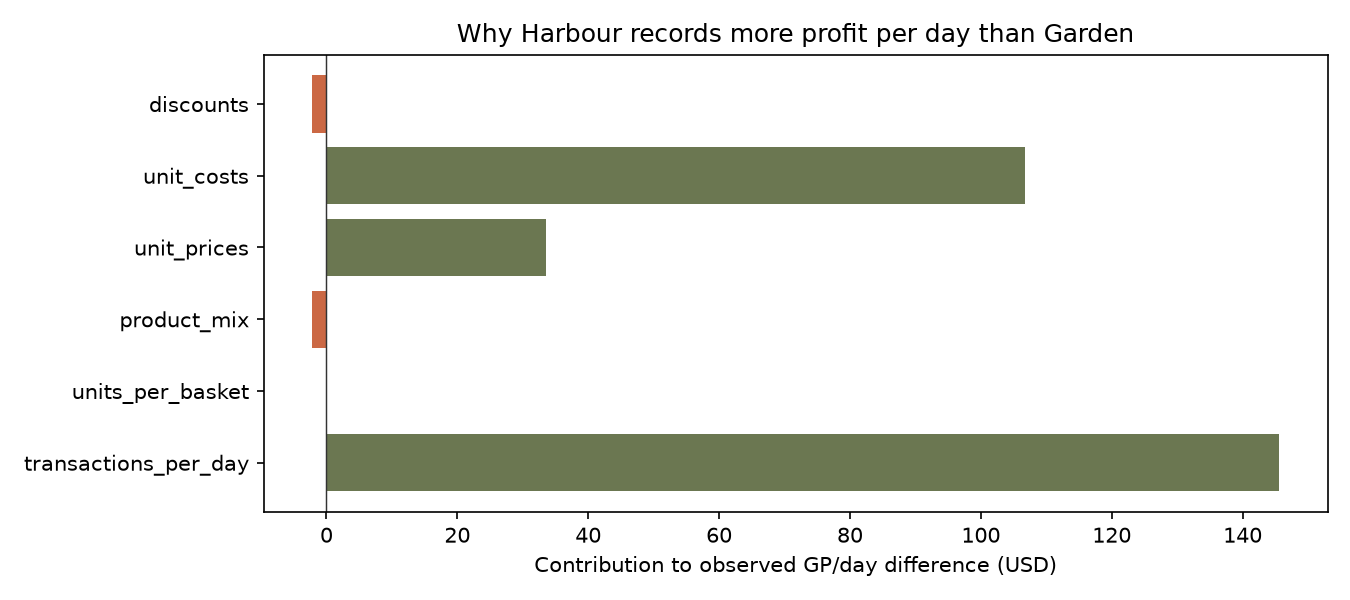

In [3]:
display(pd.Series(f['branchDecomposition']['dailyGP'], name='Recorded GP/day'))
display(pd.read_csv(O/'branch_profit_shapley.csv'))
display(Image(filename=str(ROOT/'figures/root_cause/branch_profit_decomposition.png')))

## 3. Does product mix explain Garden?

Compare the same products, rather than pooled average costs. A near-constant multiplier is compatible with standard-cost allocation or a branch-wide cost difference. Invoices, recipes and accounting definitions distinguish those mechanisms.

In [4]:
ratios = pd.read_csv(O/'matched_product_ratios.csv', index_col=0)
display(ratios.describe())
display(ratios.head(10))

,priceGardenHarbour,costGardenHarbour
count,45.000000,45.000000
mean,0.952399,1.430075
std,0.000502,0.001948
min,0.951220,1.426087
25%,0.951987,1.428954
50%,0.952576,1.430233
75%,0.952849,1.430818
max,0.953237,1.438596


,priceGardenHarbour,costGardenHarbour
Product,,
Almond Croissant,0.952849,1.429319
Americano,0.951662,1.430556
Avocado Toast,0.952621,1.430622
Banana Bread,0.952891,1.433121
Blueberry Muffin,0.951807,1.427481
Brownie,0.951941,1.430380
Butter Croissant,0.953003,1.429825
Cappuccino,0.952941,1.428571
Caramel Latte,0.951987,1.427807


## 4. Turn an unresolved cost cause into a bounded dollar decision

The fixed-Garden-volume scenario is different from the Shapley interaction allocation. Do not add them. Cost recovery fractions are hypothetical. The price alignment break-even assumes uniform unit loss and fixed mix; it is not a price-elasticity estimate.

In [5]:
display(pd.Series(f['gardenDecision'], name='Fixed-volume sensitivity'))

sixMonthRecordedCostGapAtHarbourCosts                                                   15923.47
sameVolumePriceDifferenceAtHarbourPrices                                                4985.113
recordedGP                                                                              46794.49
recordedRevenue                                                                         99748.55
uniformVolumeLossBreakEvenForPriceAlignment                                             0.096276
costRecoveryScenarios                          {'0.1': 1592.3470000000002, '0.25': 3980.86750...
interpretation                                 Fixed-volume accounting scenarios, not achieva...
Name: Fixed-volume sensitivity, dtype: object

## 5. Tuesday: more transactions or larger baskets?

Normalize by actual calendar-day exposure. Compare within complete weeks to limit long-run growth confounding. Similar category distributions are not proof of identical individuals or equivalent behavior.

{'fullWeeks': 25, 'tuesdayWins': 25, 'ratioRange': [1.444343891402715, 1.812807881773399], 'medianRatio': 1.6115942028985508}


,transactionsPerDate,ticket,unitsPerBasket,discountedBasketShare,identifiedBasketShare,takeawayShare
Tuesday,284.538462,9.028037,1.591782,0.100838,0.641660,0.416599
OtherDays,170.896774,9.027737,1.597305,0.094417,0.633735,0.406659


,False,True,difference
Category,,,
Bakery,0.216209,0.215099,-0.001110
Breakfast,0.046371,0.043563,-0.002808
Cold Coffee,0.144431,0.138757,-0.005674
Cold Drinks,0.101321,0.102157,0.000836
Desserts,0.086621,0.087126,0.000506
Hot Coffee,0.157784,0.162959,0.005175
Matcha & Tea,0.147101,0.150645,0.003544
Meals,0.027487,0.028957,0.001470
Sandwiches,0.072676,0.070737,-0.001939


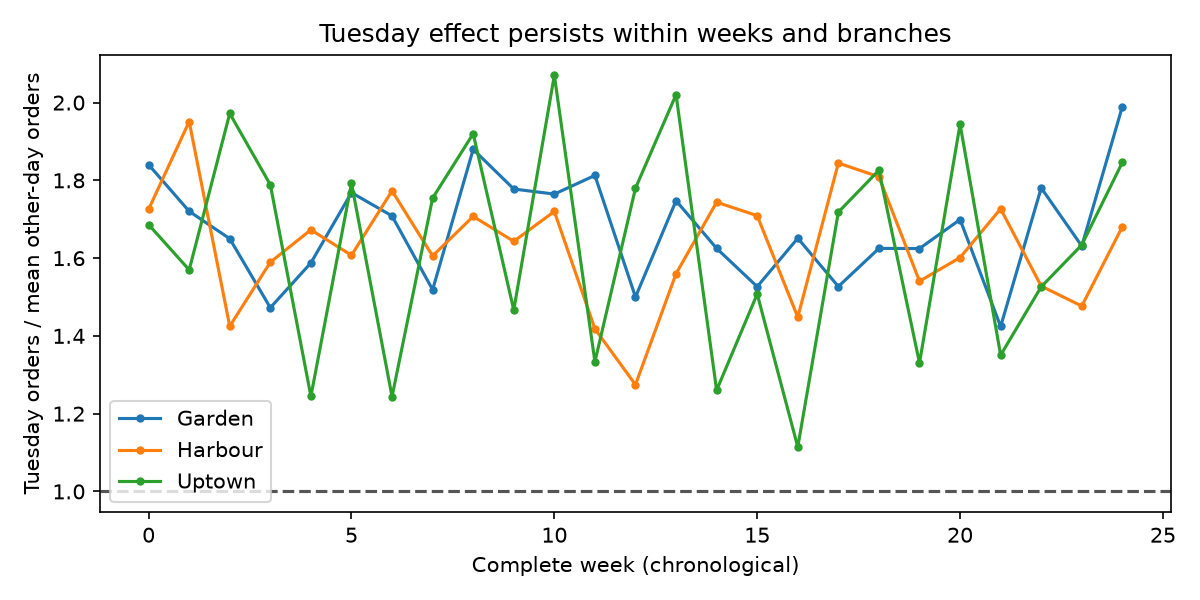

In [6]:
display(pd.DataFrame(f['tuesdayBasketComparisons']).T)
print(f['weeklyTuesday'])
display(pd.read_csv(O/'tuesday_category_mix.csv', index_col=0))
display(Image(filename=str(ROOT/'figures/root_cause/tuesday_within_week.png')))

## 6. Could this be a single branch, hour, or recorded campaign?

Test heterogeneity and exclude all dates with a recorded 15% discount anywhere in the network. This is a robustness check, not randomized treatment-effect estimation; unrecorded promotions remain possible.

In [7]:
w = pd.read_csv(O/'tuesday_by_branch_week.csv')
display(w.groupby('branch').agg(ratio_min=('ratio','min'),ratio_median=('ratio','median'),ratio_max=('ratio','max'),weeks_tuesday_wins=('tuesdayWins','sum')))
display(pd.read_csv(O/'tuesday_hour_ratios.csv'))
display(pd.Series(f['tuesdayExcluding15PercentDates'], name='Excluding campaign dates'))

,ratio_min,ratio_median,ratio_max,weeks_tuesday_wins
branch,,,,
Garden,1.424242,1.651226,1.989873,25
Harbour,1.274436,1.643154,1.951220,23
Uptown,1.114286,1.686275,2.070175,22


,hour,tuesdayTransactionsPerDay,otherTransactionsPerDay,ratio
0,7,5.692308,3.716129,1.531784
1,8,9.615385,5.096774,1.886563
2,9,13.538462,7.619355,1.776851
3,10,11.038462,7.696774,1.434167
4,11,12.576923,7.458065,1.686352
5,12,13.269231,7.690323,1.725445
6,13,14.730769,9.070968,1.623947
7,14,14.923077,8.974194,1.662888
8,15,16.269231,8.787097,1.851491
9,16,15.500000,9.387097,1.651203


observations                                                                          477
weekClusters                                                                           25
tuesdayRatioVsGeometricMeanOtherDays                                             1.647703
ci95                                               [1.5880306158286186, 1.70961800131644]
specification                           log daily transactions ~ branch×week fixed eff...
calendarProxyRatios                     {'first3': {'ratio': 1.0379342787770163, 'ci95...
Name: Excluding campaign dates, dtype: object

## 7. Investigate the payday hypothesis without inventing local facts

Exploratory log-count regression controls branch×week, weekday and illustrative days 1–3, 14–16 and 25–end. These are **not actual salary dates**. Week-clustered intervals allow common variation within each week. A weekly payday always on Tuesday cannot be separated from weekday in this file. Multiple exploratory tests and only six months limit inference.

In [8]:
display(pd.Series(f['tuesdayControlled'], name='Controlled weekday association'))
display(pd.DataFrame(f['tuesdayControlled']['calendarProxyRatios']).T)

observations                                                                          525
weekClusters                                                                           25
tuesdayRatioVsGeometricMeanOtherDays                                             1.658917
ci95                                             [1.6017268813855146, 1.7181493775140873]
specification                           log daily transactions ~ branch×week fixed eff...
calendarProxyRatios                     {'first3': {'ratio': 1.0368987304887862, 'ci95...
Name: Controlled weekday association, dtype: object

,ratio,ci95
first3,1.036899,"[0.9868295494939114, 1.0895082923293533]"
mid3,0.995134,"[0.9446433236557004, 1.048323054569282]"
end7,0.98849,"[0.9212041016417428, 1.0606897267060542]"


## 8. Growth: traffic, baskets, pricing or changing observed cohorts?

Month-length-normalized revenue/day is decomposed by transactions/day, units/basket and realized revenue/unit. Transaction growth is not proof of acquisition or footfall. Cohorts are first-observed, censored by the data window; January activity is guaranteed for the January-observed cohort.

In [9]:
display(pd.Series(f['growthAccounting']))
display(pd.DataFrame(f['identifiedGrowth']).T)
display(pd.read_csv(O/'observed_first_cohort_growth.csv').tail(12))

January                 {'transactionsPerDay': 146.61290322580646, 'un...
June                    {'transactionsPerDay': 230.2, 'unitsPerBasket'...
revenuePerDayJanuary                                          1327.276452
revenuePerDayJune                                             2088.069667
effectsRevenuePerDay    {'transactionsPerDay': 757.4498573826754, 'uni...
interpretation          More transactions is observed; increased footf...
dtype: object

,identifiedTransactions,januaryObservedCohortTransactions,januaryObservedCohortActiveCustomers,januaryObservedCohortRevenue,allIdentifiedRevenue
2026-01,2871.0,2871.0,1979.0,26087.54,26087.54
2026-06,4412.0,2469.0,1400.0,22239.78,39935.13


,month,cohort,transactions,revenue,customers
9,2026-04,2026-04,237,2108.64,159
10,2026-05,2026-01,2324,20982.43,1376
11,2026-05,2026-02,985,8752.90,601
12,2026-05,2026-03,502,4473.30,298
13,2026-05,2026-04,148,1245.42,100
14,2026-05,2026-05,104,922.67,60
15,2026-06,2026-01,2469,22239.78,1400
16,2026-06,2026-02,1096,10008.35,625
17,2026-06,2026-03,538,4826.23,323
18,2026-06,2026-04,203,1881.70,112


## Step 5 — Daily transaction distributions

Other weekdays means Monday, Wednesday, Thursday and Friday only. Weekends are visible in the plot but excluded from the comparison values. No ML is trained here. Higher pooled mean and median are descriptive; the complete-week results above address persistence separately.

Tuesday mean: 94.84615384615384
Other weekdays mean: 61.79611650485437
Tuesday median: 92.5
Other weekdays median: 59.0


,tuesdayMean,otherWeekdaysMean,tuesdayMedian,otherWeekdaysMedian,tuesdayBranchDays,otherWeekdayBranchDays,meanRatio,medianRatio
Garden,94.653846,60.815534,95.0,60.0,26.0,103.0,1.556409,1.583333
Harbour,136.730769,89.553398,136.0,88.0,26.0,103.0,1.526807,1.545455
Uptown,53.153846,35.019417,49.5,35.0,26.0,103.0,1.517839,1.414286


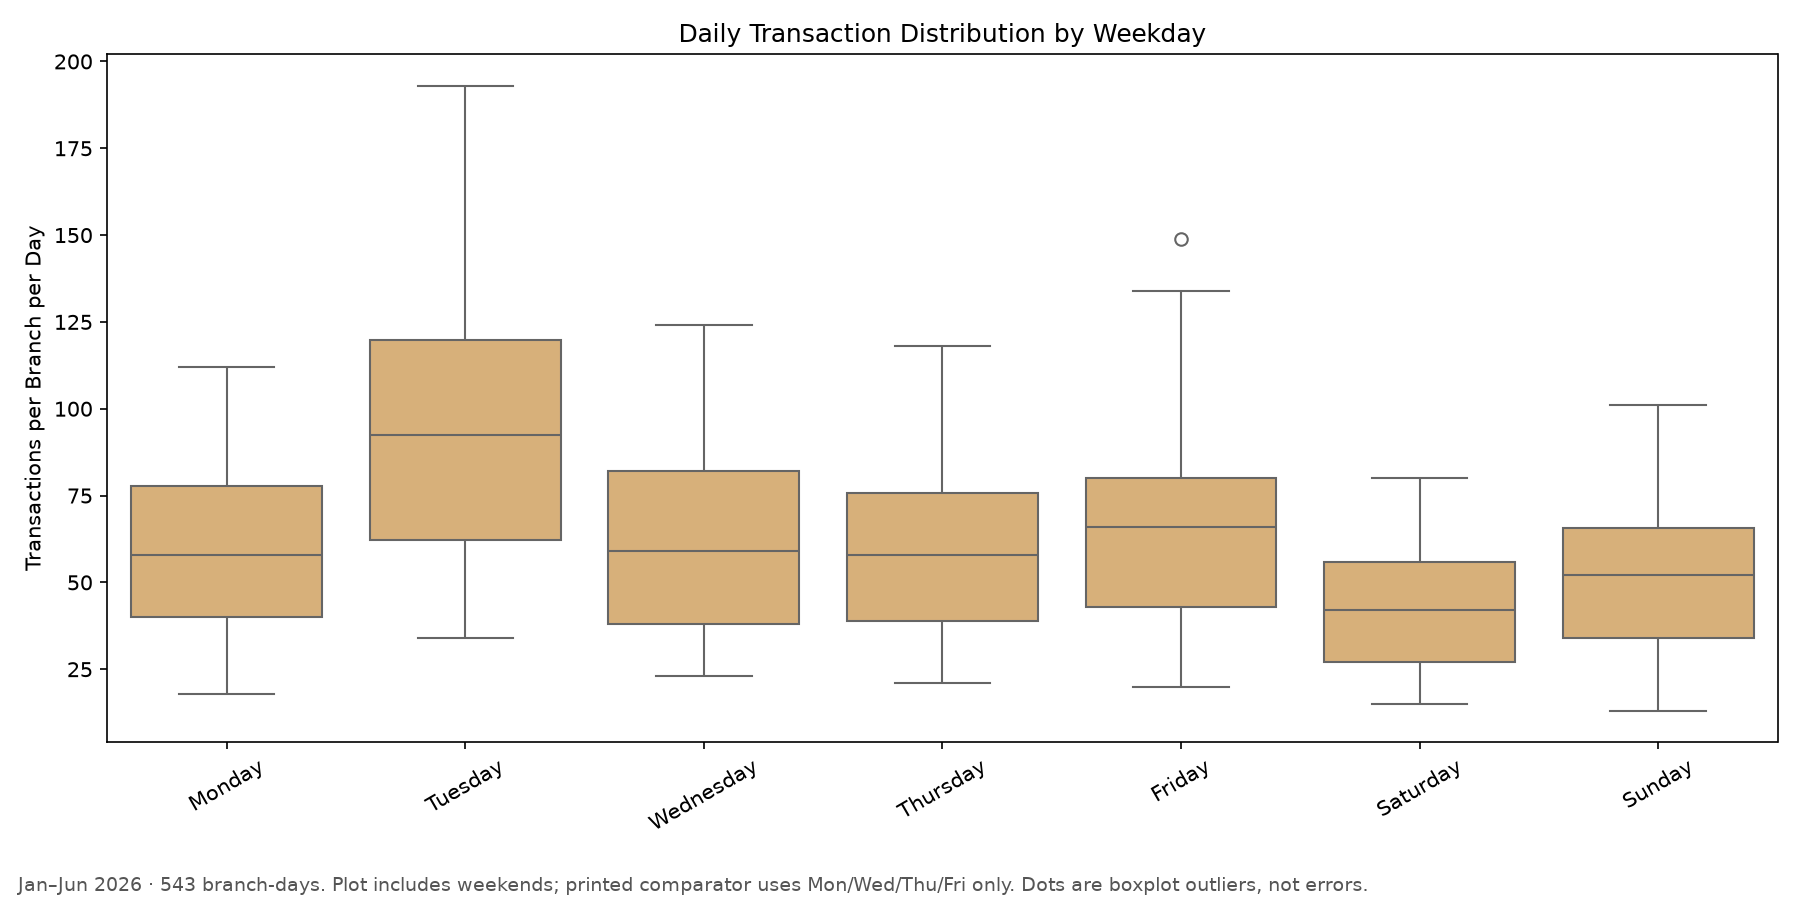

In [10]:
step5 = json.loads((ROOT/'reports/activity/step5_tuesday_distribution.json').read_text())
for label, key in [('Tuesday mean','tuesdayMean'),('Other weekdays mean','otherWeekdaysMean'),('Tuesday median','tuesdayMedian'),('Other weekdays median','otherWeekdaysMedian')]: print(label + ':', step5[key])
display(pd.DataFrame(step5['byBranch']).T)
display(Image(filename=str(ROOT/'figures/activity/tuesday_weekday_boxplot.png')))

## 9. Competing hypotheses, required evidence, and financial decisions

The detailed report ranks cost reconciliation, Tuesday calendar/provenance investigation and growth-mechanism validation ahead of additional product features. No new promotion or loyalty claim is needed to establish an accounting finding.

In [11]:
display(Markdown((O/'REPORT.md').read_text()))

# Root-cause investigation: explain the dollars before designing offers

## What changes in the project

Lead with a reproducible investigation of recorded profit and transaction differences. Keep forecasting as supporting validation and operational infrastructure. The camera, loyalty concepts and bundle planner are prototypes; they do not establish a root cause or a measured financial benefit. We should not use technical complexity as evidence of originality. The user-supplied `01_eda.ipynb` is a useful starting analysis, not a set of instructions or proof that its assumptions are true. It remains untouched.

## 1. Why does Harbour record more gross profit than Garden?

Observed GP per calendar day: Harbour **$540.08**, Garden **$258.53**. Gap: **$281.54/day**. An exact accounting decomposition separates six factors in the identity:

`GP/day = transactions/day × units/transaction × Σ product unit share × [price × (1 − effective discount) − unit cost]`.

All 720 possible orders of changing the six factors from Garden to Harbour are averaged (Shapley decomposition). This allocates interaction terms symmetrically rather than choosing a convenient order. Rounding is included in the effective discount so the identity reproduces the recorded money exactly.

| Accounting factor | Contribution to observed GP/day gap | Share of net gap |
|---|---:|---:|
| transactions_per_day | $145.58 | 51.7% |
| units_per_basket | $-0.01 | -0.0% |
| product_mix | $-2.22 | -0.8% |
| unit_prices | $33.59 | 11.9% |
| unit_costs | $106.80 | 37.9% |
| discounts | $-2.19 | -0.8% |

Negative entries offset the positive contributions; positive shares can sum above 100%. These are contributions to an **observed accounting gap**, not causal effects or savings. In particular, the transaction-count contribution does not show whether Harbour has better location, marketing, footfall or conversion. We need storefront visitor counts and campaign exposure to distinguish them.

![Profit decomposition](../../figures/root_cause/branch_profit_decomposition.png)

### Rule out the obvious alternative: product mix

For all 45 matched products, Garden's price/Harbour price is 0.953 at the median, with a narrow 0.951–0.953 range. Its cost ratio is 1.430, range 1.426–1.439. The price and cost differences exist **within the same products**, not just because Garden sells different items. Matching products and the small Shapley mix contribution weaken product mix as an explanation for the profit gap.

Every branch/product price and unit cost is constant over the observation window. A near-uniform branch cost multiplier across coffee, food and packaged drinks is compatible with a standard-cost allocation rule as well as a real branch-wide procurement or recipe difference. It cannot identify which. The smaller Uptown branch has lower recorded unit costs than Harbour, so a simple 'small branch ⇒ higher cost' narrative does not fit the ordering; this does not rule out other scale effects.

### Investigate the mechanism, then size a decision

| Competing explanation | What this file tests | Evidence needed to distinguish it | Action if confirmed |
|---|---|---|---|
| Different overhead allocation | Near-uniform multiplier is compatible; not proof | Finance cost formula, chart of accounts and allocations for identical SKUs | Normalize reporting; do not call accounting reclassification cash savings |
| Supplier/transfer-price difference | Same-product gap exists; invoices absent | Landed-cost invoices and transfer prices for matched products on matched dates | Negotiate or standardize sourcing only after measuring total landed cost |
| Recipe/portion/waste difference | Standard recorded costs are fixed; actual usage absent | Recipe grams, yields, inventory movements, waste and sampled portions | Change the operational process responsible; include quality/service tradeoffs |
| Local pricing strategy | Garden price is consistently lower; elasticity unobserved | Local demand context and a controlled pricing test | Adjust only if net GP and customer response justify it |

At **Garden's own observed quantities**, replacing only recorded costs with Harbour's gives a six-month accounting sensitivity of **$15,923.47**. This differs from the Shapley cost contribution because the latter averages interactions with both branches' volumes and other factors. Do not add the two figures.

If 10%, 25% or 50% of that fixed-volume gap is genuinely removable cash cost, the corresponding six-month scenarios are **$1,592.35**, **$3,980.87** or **$7,961.74**, before implementation costs. If the whole gap is only allocation, avoidable cost may be zero. No annual extrapolation is used as the headline.

Aligning Garden prices with Harbour at unchanged volumes and discount percentages adds **$4,985.11** in six-month revenue and GP. Under a **uniform volume-loss, unchanged-mix and unchanged-unit-cost assumption**, a loss of about **9.6%** of units would erase that GP improvement. This is a break-even boundary, not an elasticity estimate or a recommendation to raise prices now.

## 2. Why does Tuesday outperform?

We can identify the measured mechanism—**more transactions rather than higher spending per basket**—and test competing explanations. The ultimate behavioral reason remains unidentified.

- Tuesday is the highest network transaction day in **25 of 25 complete weeks**. Comparing each Tuesday to the mean of the other days in the same week gives ratios from **1.44 to 1.81**, median **1.61**. This avoids treating late-period growth as a weekday effect.
- Tuesday mean basket revenue is **$9.0280** versus **$9.0277** on other days. Average basket sizes are **1.592** versus **1.597** units.
- Tuesday category unit shares have total-variation distance **1.15%** from other days. This is descriptive closeness, not a formal equivalence test or evidence that the same people visit.
- Across all 17 recorded hours, Tuesday/other-day average transaction ratios remain above 1, ranging **1.43–1.89**. The pattern is broader than one evening slot. Per-branch/week results are in [CSV](tuesday_by_branch_week.csv).

![Within-week Tuesday test](../../figures/root_cause/tuesday_within_week.png)

### Step 5 — Tuesday daily distributions (weekday-only comparator)

The requested code was run on unique transaction counts for each branch/date. All three branches have records on all 181 dates: **543 branch-days** in total. Tuesday has **78 branch-days**; the comparator has **309**. Here **other weekdays means Monday, Wednesday, Thursday and Friday only**. Saturday and Sunday appear in the boxplot but are excluded from the four printed comparison values. This differs from earlier comparisons against all six non-Tuesday days.

| Printed statistic | Transactions per branch-day |
|---|---:|
| Tuesday mean | 94.846154 |
| Other weekdays mean | 61.796117 |
| Tuesday median | 92.500000 |
| Other weekdays median | 59.000000 |

![Daily transaction distributions by weekday](../../figures/activity/tuesday_weekday_boxplot.png)

Both pooled Tuesday mean and median exceed the weekday-only comparator. The mean ratio is **1.535×**; the median ratio is **1.568×**. A higher median supports a shift in typical observed activity rather than relying only on the mean. It does not alone prove that exceptional dates play no role: branch scales and long-run growth are mixed together in the pooled boxes.

| Branch | Tuesday mean | Other weekday mean | Tuesday median | Other weekday median |
|---|---:|---:|---:|---:|
| Garden | 94.65 | 60.82 | 95.00 | 60.00 |
| Harbour | 136.73 | 89.55 | 136.00 | 88.00 |
| Uptown | 53.15 | 35.02 | 49.50 | 35.00 |

[Branch-stratified boxplots](../../figures/activity/tuesday_weekday_boxplot_by_branch.png) use the same vertical scale and show that the mean and median direction is shared by each branch. No formal significance claim is made. The earlier complete-week analysis is the stronger persistence check: Tuesday was the busiest network day in all 25 complete weeks, which is evidence beyond these pooled distributions. Neither check identifies customer motivation, payroll timing, promotion effects or achievable extra profit.

Reproduce: `python3 src/tuesday_distribution.py --data /path/to/stories_transactions.csv`. [Four values and branch diagnostics](../activity/step5_tuesday_distribution.json); [daily counts](../activity/step5_daily_transactions.csv). **No model was trained in Step 5.**


### Is 'people got paid' supported?

We tested **illustrative** calendar proxies: days 1–3, 14–16 and 25–month end. These are not actual local salary dates: the dataset supplies no country, payroll schedule or verified calendar. We fit log daily transactions with branch×week fixed effects, weekday indicators and those calendar proxies, using 525 branch-day observations in 25 complete weeks. Standard errors cluster by week to account for common variation across branches and days. Intervals are exploratory; model choice and multiple hypotheses were not pre-registered, only six months exist, and cross-week dependence may remain.

The adjusted Tuesday ratio versus the **geometric mean** of other weekday counts is **1.659**, 95% interval **1.602–1.718**. This is a conditional association in log counts, not an estimate of what changing a date would cause.

| Hypothetical calendar window | Adjusted count ratio | Exploratory 95% interval |
|---|---:|---:|
| first3 | 1.037 | 0.987–1.090 |
| mid3 | 0.995 | 0.945–1.048 |
| end7 | 0.988 | 0.921–1.061 |

None of these monthly-date proxy intervals excludes 1. The calendar controls do not explain away the Tuesday association. **This does not disprove payday effects**: a weekly payday that always lands on Tuesday is observationally confounded with weekday, and different salary schedules were not observed. Do not invent a country, payday or local explanation to complete the story.

### Is the recorded 15% campaign the explanation?

Removing **all 16 dates** on which any branch has a 15% line discount—including observations at other branches on those dates—still gives a Tuesday ratio of **1.648**, interval **1.588–1.710**. That weakens the explanation that these recorded campaign dates alone create the recurring Tuesday pattern. It does not identify discount effectiveness or exclude unrecorded recurring offers.

| Behavioral hypothesis | Current status | Discriminating next evidence |
|---|---|---|
| Month-end/midmonth salary timing | Tested proxies do not explain the recurring Tuesday effect | Actual local pay calendar; customer/source-of-visit evidence; more months |
| Weekly payday, recurring event or hidden Tuesday promotion | Still plausible and indistinguishable here | Promotion/event calendar including off-POS channels and associated campaign costs |
| Bigger baskets or category shift | Not the main arithmetic mechanism in this data | Controlled customer/occasion study if a behavioral claim is needed |
| A particular branch or isolated hour | Pattern is broad across branches/hours; inspect CSV heterogeneity | Local footfall and operating schedules by site |
| Construction or anonymization artifact | Possible; `SYN-` prefix or regular patterns alone do not prove it | Data provenance, replacement-ID procedure and whether a date multiplier was applied |

The next useful step is to reconcile the Tuesday calendar with Stories' promotion and operations records. If a hidden promotion exists, assess **total contribution net of campaign cost**, rather than copy the pattern into a new discount. If the pattern reflects provenance transformations, do not base a real staffing or pricing intervention on it. Without labor, inventory and lost-sale records, we cannot price the value of extra staffing or preparation.

## 3. What is driving growth—and what is not?

Network revenue per calendar day rises from **$1,327.28 in January** to **$2,088.07 in June**. A three-factor Shapley identity decomposes the change into:

- Transactions/day: **+$757.45/day**.
- Units/basket: **+$3.44/day**.
- Realized revenue/unit: **$-0.10/day**.

Approximately 99.6% of the accounting increase comes from transaction counts. That does not establish customer acquisition: one person can make multiple purchases and footfall is unobserved.

A useful countercheck to the supplied notebook's growth narrative: the **January first-observed customer cohort** contributes 2,871 transactions in January versus 2,469 in June, and revenue **$26,087.54** versus **$22,239.78**. Overall identified transactions nevertheless rise from 2,871 to 4,412. Later first-observed cohorts contribute to that composition change. This neither proves acquisition nor a retention failure: first-observed dates are censored by the file start, January cohort selection guarantees January activity, and customer-ID capture/provenance is uncertain. See [cohort CSV](observed_first_cohort_growth.csv).

## 4. Resolve notebook assumptions rather than silently inheriting them

The supplied notebook drops 132 exact duplicate rows, interpreting them as POS/export duplication. Repeated identical lines can also be genuine two-item entries. Both representations must be checked until POS logs resolve the issue. Excluding them changes revenue by **$741.43** and the Garden cost sensitivity from **$15,923.47** to **$15,887.50**. The main economic issue is robust, but the duplicate mechanism is not established.

Other distinctions matter: recorded sales hours do not prove opening hours; missing customer ID does not prove nonmembership; first-observed customers do not prove new customers; a branch-choice simulation matching the observed distribution does not prove IDs are randomized. Customer-level conclusions require corroboration rather than automatic rejection or acceptance.

## Decision priority and evidence request

1. **Finance/operations cost reconciliation first.** Compare the five Garden products with the largest dollar cost gaps against Harbour invoices, standard-cost formulas, recipes and waste. Determine which components are avoidable cash cost. Quantified opportunity is a bounded scenario, not a promise.
2. **Investigate the common Tuesday mechanism.** Join a verified promotion/event calendar and data-provenance description to the date/branch panel. If neither explains it, collect customer occasion and footfall evidence. Record disconfirming evidence as well as a preferred story.
3. **Validate the growth mechanism.** Join footfall/conversion and stable customer identity before choosing acquisition, retention or basket expansion as the intervention.
4. **Use the forecasts and offer planner downstream.** They can support a tested intervention once the business mechanism is understood. No additional cashback, camera or bundle feature is needed to establish these findings.

## Reproduce and inspect

`python3 src/root_cause.py --data /path/to/stories_transactions.csv` generates the [machine-readable findings](findings.json), detailed CSVs and figures. The executed notebook is `notebooks/02_root_cause_investigation.ipynb`. Raw input and the user's notebook are unchanged. Source SHA-256: `f1672e728c28295b2b802d878fd38a158ba039827b429355e8438ee0463237a1`. All dollar comparisons refer to the observed six-month file or explicitly identified daily amounts; none is an observed treatment benefit.
